In [ ]:
%pip install opencv-python pandas seaborn matplotlib gdown scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 15.6 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 28.0 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
import gdown
import zipfile
from pathlib import Path

FILE_ID = '1PP09vNLPEsiFXFyKu4_8mC-bFJbxfflC' 

url = f'https://drive.google.com/uc?id={FILE_ID}'
zip_output = 'tumors_dataset.zip'
extract_dir = 'extract/'


try:
    if not os.path.exists(zip_output):
        gdown.download(url, zip_output, quiet=False)

    with zipfile.ZipFile(zip_output, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

    data_path = Path(extract_dir)
    if (data_path / 'Data').exists():
        data_path = data_path / 'Data'
    elif (data_path / 'tumors' / 'Data').exists():
        data_path = data_path / 'tumors' / 'Data'

    print(f"Targeting data directory at: {data_path}")


except Exception as e:
    print(f"\n An error occurred: {e}")
    print("Please check your file ID, folder nesting inside the ZIP, or Drive permissions.")

Targeting data directory at: extract/Data


In [ ]:
# import zipfile
# with zipfile.ZipFile("/content/drive/MyDrive/datasets/data.zip","r") as zip_file:
#   zip_file.extractall("/content")

In [ ]:
import glob
import cv2
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [ ]:
extention_images = {".jpeg", ".jpg", ".bmp", ".png"}
DATA_DIREC = data_path
files_images = []
classes = ["notumor","pituitary","meningioma","glioma"]

for class_name in classes:
    class_path = DATA_DIREC/class_name

    files = [
        file for file in class_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in extention_images
    ]

    files_images.extend(
        (file, class_name) for file in files
    )

print(" nombre total d'images :", len(files_images))

 nombre total d'images : 7023


In [ ]:
# creation un dataframe des images :

df_images = pd.DataFrame(files_images,columns=["path", "label"])

print(df_images.head())

print("\nNombre d'images par classe :")
print(df_images["label"].value_counts())

                                    path    label
0  extract/Data/notumor/Te-noTr_0000.jpg  notumor
1  extract/Data/notumor/Te-noTr_0001.jpg  notumor
2  extract/Data/notumor/Te-noTr_0002.jpg  notumor
3  extract/Data/notumor/Te-noTr_0003.jpg  notumor
4  extract/Data/notumor/Te-noTr_0004.jpg  notumor

Nombre d'images par classe :
label
notumor       2000
pituitary     1757
meningioma    1645
glioma        1621
Name: count, dtype: int64


**Charger les images avec OpenCV**

In [ ]:
# Redimensionner les images à une taille fixe (ex. 224×224) à l'aide de la bibliothèque OpenCV:

images = []
labels = []

for file_path, label in files_images:
    try:
        image = cv2.imread(str(file_path))

        if image is None:
            print("-- image illisible :", file_path)
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        image = cv2.resize(image, (224, 224))

        images.append(image)
        labels.append(label)

    except Exception as error:
        print("Erreur :", file_path, error)
        continue

print("Images chargees :", len(images))
print("Labels charges :", len(labels))

Images chargees : 7023
Labels charges : 7023


In [ ]:
# Convertir les listes d'images et d'étiquettes en tableaux NumPy pour les rendre exploitables par le modèle:

X = np.array(images, dtype=np.uint8)
y = np.array(labels)

print("X shape :", X.shape)
print("y shape :", y.shape)
print("Classes :", np.unique(y))

X shape : (7023, 224, 224, 3)
y shape : (7023,)
Classes : ['glioma' 'meningioma' 'notumor' 'pituitary']


glioma : 1621 images
meningioma : 1645 images
notumor : 2000 images
pituitary : 1757 images


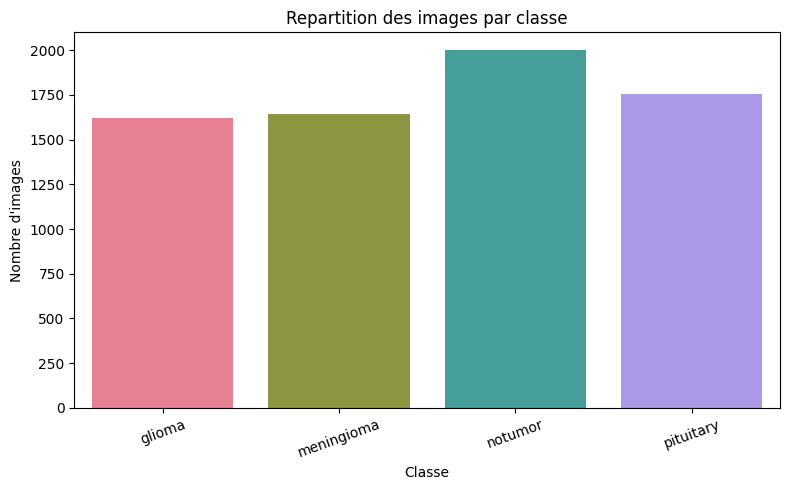

In [ ]:
# Conmter le nombre d'images par classe
classes, counts = np.unique(y, return_counts=True)

# Afficher les résultats
for classe, nombre in zip(classes, counts):
    print(f"{classe} : {nombre} images")

plt.figure(figsize=(8, 5))

sns.barplot(x=classes, y=counts, hue=classes, palette="husl",legend=False)

plt.title("Repartition des images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

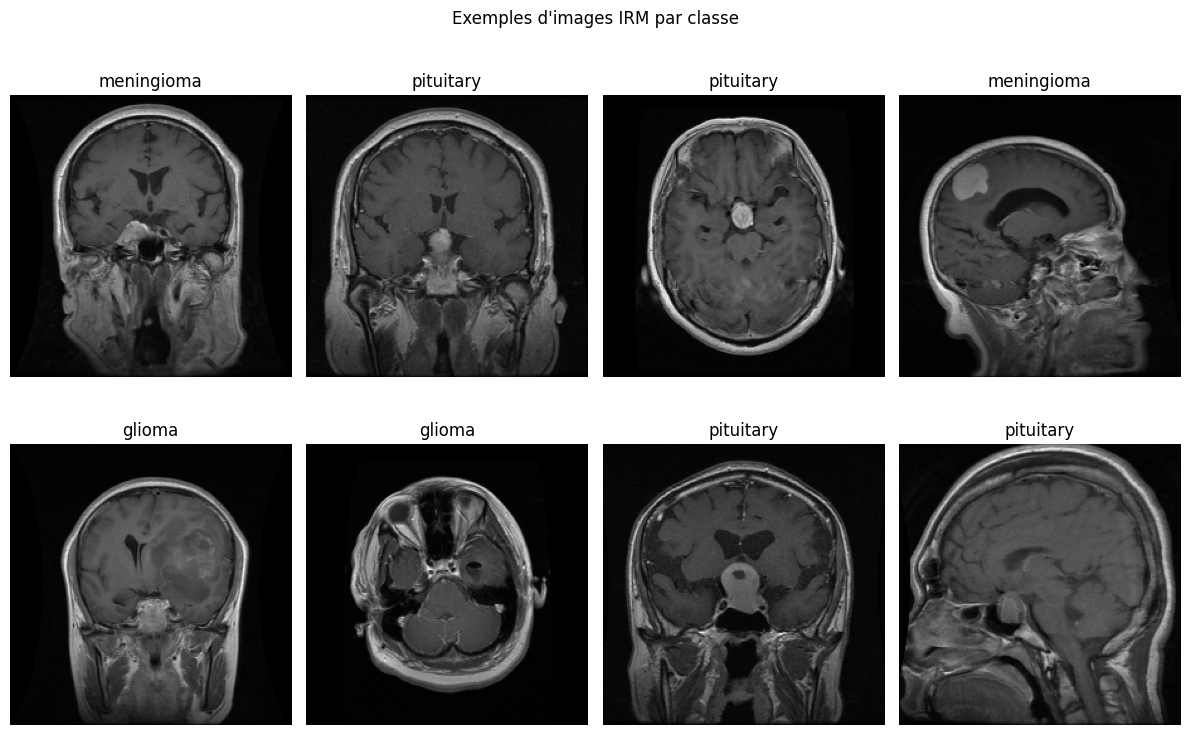

In [ ]:
# Afficher 8 images aléatoires

np.random.seed(42)

nombre_images = min(8, len(X))
indices = np.random.choice(len(X), size=nombre_images, replace=False)

plt.figure(figsize=(12, 8))

for position, index in enumerate(indices):
    plt.subplot(2, 4, position + 1)
    plt.imshow(X[index])
    plt.title(y[index])
    plt.axis("off")

plt.suptitle("Exemples d'images IRM par classe")
plt.tight_layout()
plt.show()


In [ ]:
# -----------------------------------------

print("Type des donnees :", X.dtype)
print("Valeur minimale des pixels :", X.min())
print("Valeur maximale des pixels :", X.max())
print("Dimensions des images :", X.shape[1:])


Type des donnees : uint8
Valeur minimale des pixels : 0
Valeur maximale des pixels : 255
Dimensions des images : (224, 224, 3)


In [ ]:
from sklearn.model_selection import train_test_split

# 70 % train et 30 % temporaire
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 15 % validation et 15 % test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# verifier les dimensions

print("X_train :", X_train.shape)
print("X_val   :", X_val.shape)
print("X_test  :", X_test.shape)

print("y_train :", y_train.shape)
print("y_val   :", y_val.shape)
print("y_test  :", y_test.shape)


X_train : (4916, 224, 224, 3)
X_val   : (1053, 224, 224, 3)
X_test  : (1054, 224, 224, 3)
y_train : (4916,)
y_val   : (1053,)
y_test  : (1054,)


In [ ]:
# encoding

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
encoder.fit(y)

y_train_encoded = encoder.transform(y_train)
y_val_encoded = encoder.transform(y_val)
y_test_encoded = encoder.transform(y_test)

class_names = encoder.classes_
num_classes = len(class_names)

print("Classes :", class_names)
print("Nombre de classes :", num_classes)

print("\nExemples de labels avant encodage :", y_train[:10])
print("Exemples de labels après encodage :", y_train_encoded[:10])


Classes : ['glioma' 'meningioma' 'notumor' 'pituitary']
Nombre de classes : 4

Exemples de labels avant encodage : ['glioma' 'notumor' 'meningioma' 'glioma' 'pituitary' 'glioma' 'notumor'
 'notumor' 'pituitary' 'meningioma']
Exemples de labels après encodage : [0 2 1 0 3 0 2 2 3 1]


In [ ]:
#  augmentation :

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential(
    [
        layers.RandomRotation(0.03),
        layers.RandomZoom(0.05),
        layers.RandomTranslation(
            height_factor=0.03,
            width_factor=0.03
        )
    ],
    name="data_augmentation"
)


2026-10-29 22:23:29.167675: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793312609.230335    3528 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793312609.248584    3528 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793312609.373422    3528 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793312609.373452    3528 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793312609.373460    3528 computation_placer.cc:177] computation placer alr

# création et entraînement du modèle CNN



In [ ]:
# Créer le modèle CNN

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Rescaling(1.0 / 255),

    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(num_classes, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,764 (397.52 KB)

 Trainable params: 101,764 (397.52 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compiler le modèle


model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)



In [ ]:
from tensorflow import keras

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath="../models/neurovision_best.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", 
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

callbacks_list = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]



In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train_encoded)).shuffle(1000).batch(32).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val_encoded)) .batch(32).prefetch(tf.data.AUTOTUNE)

In [ ]:

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    batch_size=32,
    callbacks=[callbacks_list],
    verbose=1
)


Epoch 1/15


I0000 00:00:1793312623.290061    3817 cuda_dnn.cc:529] Loaded cuDNN version 92400


154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.3271 - loss: 1.2963
Epoch 1: val_loss improved from None to 1.00711, saving model to ../models/neurovision_best.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - accuracy: 0.4225 - loss: 1.1983 - val_accuracy: 0.5869 - val_loss: 1.0071 - learning_rate: 0.0010
Epoch 2/15
153/154 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5543 - loss: 1.0517
Epoch 2: val_loss did not improve from 1.00711
154/154 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.5938 - loss: 0.9883 - val_accuracy: 0.3685 - val_loss: 1.6267 - learning_rate: 0.0010
Epoch 3/15
153/154 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6154 - loss: 0.9114
Epoch 3: val_loss did not improve from 1.00711

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
154/154 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.6279 - loss: 0.8887 - val_accuracy: 0.4577 - val_loss: 1.3614 - learning_rate: 0.0010
Epoch 4/15
153/154 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step -

In [ ]:
# # # Charger le meilleur modele sauvegarde
# best_model = keras.models.load_model("../models/neurovision_best.keras")

# print("Meilleur modèle charge avec succees.")

# test_loss, test_accuracy = best_model.evaluate(
#     X_test,
#     y_test_encoded,
#     verbose=1
# )

# print(f"Test Loss     : {test_loss:.4f}")
# print(f"Test Accuracy : {test_accuracy:.2%}")


In [ ]:
# # Predictions du meilleur modele

# from sklearn.metrics import classification_report, confusion_matrix
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns

# y_pred_proba = best_model.predict(X_test, verbose=1)
# y_pred = np.argmax(y_pred_proba, axis=1)


# print(classification_report(
#     y_test_encoded,
#     y_pred,
#     labels=np.arange(num_classes),
#     target_names=class_names,
#     zero_division=0
# ))

# cm = confusion_matrix(
#     y_test_encoded,
#     y_pred,
#     labels=np.arange(num_classes)
# )

# plt.figure(figsize=(8, 6))
# sns.heatmap(
#     cm,
#     annot=True,
#     fmt="d",
#     cmap="Blues",
#     xticklabels=class_names,
#     yticklabels=class_names
# )

# plt.title("Matrice de confusion - Meilleur CNN")
# plt.xlabel("Classe predite")
# plt.ylabel("Classe reelle")
# plt.tight_layout()
# plt.show()


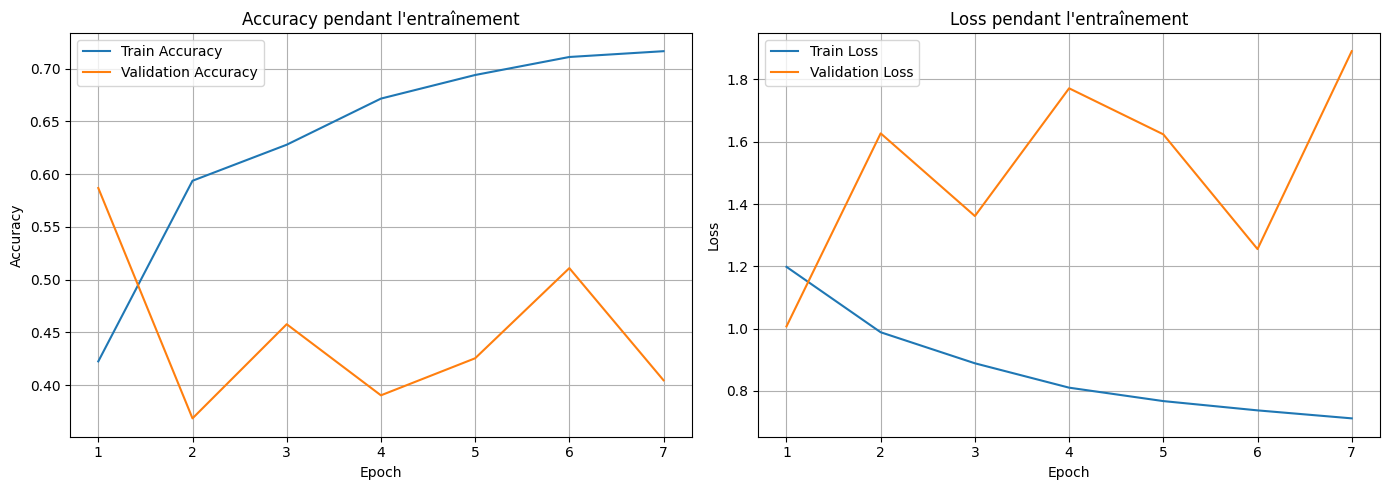

In [ ]:
# Visualiser les resultats de l'entraînement

train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, train_accuracy, label="Train Accuracy")
axes[0].plot(epochs_range, val_accuracy, label="Validation Accuracy")
axes[0].set_title("Accuracy pendant l'entraînement")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_range, train_loss, label="Train Loss")
axes[1].plot(epochs_range, val_loss, label="Validation Loss")
axes[1].set_title("Loss pendant l'entraînement")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
modele_charge = keras.models.load_model("../models/neurovision_best.keras")

modele_charge.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305,294 (1.16 MB)

 Trainable params: 101,764 (397.52 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,530 (795.04 KB)

In [ ]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

#un function qui fait un processing d'un image avons la predection :

def predire_image(chemin_image):
    chemin_image = Path(chemin_image)

    if not chemin_image.exists():
        print("Erreur : image introuvable :", chemin_image)
        return

    image = cv2.imread(str(chemin_image))

    if image is None:
        print("Erreur : impossible de lire cette image.")
        return

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    image = cv2.resize(image, (224, 224))

    image_batch = np.expand_dims(image, axis=0)

    probabilites = modele_charge.predict(image_batch, verbose=0)[0]

    indice_predit = np.argmax(probabilites)
    classe_predite = class_names[indice_predit]
    score = probabilites[indice_predit]

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Prédiction : {classe_predite}\nScore : {score:.2%}")
    plt.show()

    print("Classe prédite :", classe_predite)
    print(f"Score du modèle : {score:.2%}")

    # Afficher le score de chaque classe
    print("\nScores par classe :")
    for nom_classe, probabilite in zip(class_names, probabilites):
        print(f"{nom_classe} : {probabilite:.2%}")


In [ ]:
# upload un image pour le test :

# from google.colab import files

# uploaded = files.upload()

In [ ]:
# predire_image("gliome_de_bas_grade.png")


# Partie 2 avec MobileNetV2


**Fine-tuning**

In [ ]:
# verification des donnees prepares : les dimensions des images et des labels

print("X_train :", X_train.shape)
print("X_val   :", X_val.shape)
print("X_test  :", X_test.shape)

print("y_train :", np.shape(y_train))
print("y_val   :", np.shape(y_val))
print("y_test  :", np.shape(y_test))

print("\nType des images :", X_train.dtype)
print("Valeur minimale :", np.min(X_train))
print("Valeur maximale :", np.max(X_train))

print("\nClasses encodes dans y_train :",np.unique(y_train))


X_train : (4916, 224, 224, 3)
X_val   : (1053, 224, 224, 3)
X_test  : (1054, 224, 224, 3)
y_train : (4916,)
y_val   : (1053,)
y_test  : (1054,)

Type des images : uint8
Valeur minimale : 0
Valeur maximale : 255

Classes encodes dans y_train : ['glioma' 'meningioma' 'notumor' 'pituitary']


In [ ]:
# Charger MobileNetV2 sans sa tête de classification originale

import tensorflow as tf
from tensorflow.keras import layers, Model

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# nomber de couches de la base
print("Nombre de couches :", len(base_model.layers))


base_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Nombre de couches : 154


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 2,223,872 (8.48 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [ ]:
# gele de la base pre-entraine

base_model.trainable = False


In [ ]:
# ajouter une tête de classification pour 4 classes

from tensorflow.keras import layers, Model

inputs = layers.Input(shape=(224, 224, 3))

x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.2)(x)

outputs = layers.Dense(4, activation="softmax")(x)

model = Model(inputs=inputs, outputs=outputs)



In [ ]:
# Compiler le modele avec un optimiseur adapté (ex. Adam).

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
#  Vérifier l'architecture avec model.summary()
model.summary()


Model: "functional_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# Entraîner la tête et mesurer la durée
import time

EPOCHS = 10
BATCH_SIZE = 32

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath="neurovision_best.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

callbacks_list = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]


start_time = time.time()

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train_encoded)).shuffle(1000).batch(32).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val_encoded)) .batch(32).prefetch(tf.data.AUTOTUNE)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    batch_size=32,
    callbacks=callbacks_list,
    verbose=1
)

end_time = time.time()
training_duration = end_time - start_time

print(f"Durée d'entraînement : {training_duration:.2f} secondes")
print(f"Durée d'entraînement : {training_duration / 60:.2f} minutes")


Epoch 1/15


I0000 00:00:1793312699.148710    3818 service.cc:152] XLA service 0x7f5f90052340 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793312699.148747    3818 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 3060, Compute Capability 8.6
2026-10-29 22:24:59.309867: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


  7/154 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.4804 - loss: 1.3568 

I0000 00:00:1793312706.950970    3818 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.6804 - loss: 0.8099

2026-10-29 22:25:20.761557: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1174', 636 bytes spill stores, 636 bytes spill loads

2026-10-29 22:25:20.782216: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1174', 884 bytes spill stores, 884 bytes spill loads

2026-10-29 22:25:25.775319: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1174', 644 bytes spill stores, 644 bytes spill loads

2026-10-29 22:25:26.004610: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1174', 836 bytes spill stores, 836 bytes spill loads




Epoch 1: val_loss improved from None to 0.37802, saving model to neurovision_best.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 37s 161ms/step - accuracy: 0.7742 - loss: 0.5946 - val_accuracy: 0.8585 - val_loss: 0.3780 - learning_rate: 0.0010
Epoch 2/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8545 - loss: 0.3835
Epoch 2: val_loss improved from 0.37802 to 0.31330, saving model to neurovision_best.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.8651 - loss: 0.3622 - val_accuracy: 0.8765 - val_loss: 0.3133 - learning_rate: 0.0010
Epoch 3/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8788 - loss: 0.3139
Epoch 3: val_loss improved from 0.31330 to 0.27874, saving model to neurovision_best.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.8879 - loss: 0.2971 - val_accuracy: 0.8936 - val_loss: 0.2787 - learning_rate: 0.0010
Epoch 4/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8974 - loss: 0.2729
Epoch 4: val_loss improved from 0.27874 

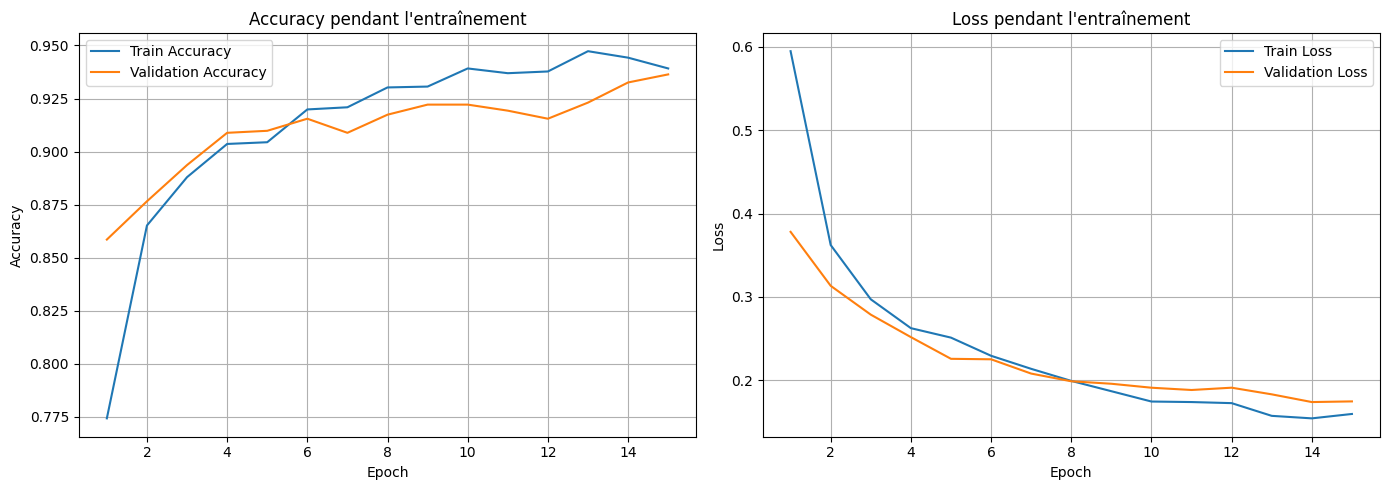

In [ ]:
# Visualiser les courbes d'apprentissage

import matplotlib.pyplot as plt

acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, acc, label="Train Accuracy")
axes[0].plot(epochs_range, val_acc, label="Validation Accuracy")
axes[0].set_title("Accuracy pendant l'entraînement")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_range, loss, label="Train Loss")
axes[1].plot(epochs_range, val_loss, label="Validation Loss")
axes[1].set_title("Loss pendant l'entraînement")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


# Fine-tuning

In [ ]:
# Sauvegarder les resultats de la phase Transfer Learning

baseline_loss, baseline_accuracy = model.evaluate(X_val, y_val_encoded, verbose=0)

transfer_learning_results = {
    "val_loss": baseline_loss,
    "val_accuracy": baseline_accuracy
}

print("Résultats avant fine-tuning :")
print(f"Validation Loss     : {baseline_loss:.4f}")
print(f"Validation Accuracy : {baseline_accuracy:.4f}")


Résultats avant fine-tuning :
Validation Loss     : 0.1739
Validation Accuracy : 0.9326


In [ ]:
# Dégeler une partie des dernières couches

base_model.trainable = True

N_DERNIERES_COUCHES = 30

for layer in base_model.layers[:-N_DERNIERES_COUCHES]:
    layer.trainable = False

for layer in base_model.layers[-N_DERNIERES_COUCHES:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

nb_couches_trainables = sum(layer.trainable for layer in base_model.layers)

print("Nombre total de couches :", len(base_model.layers))
print("Nombre de couches entraînables :", nb_couches_trainables)


Nombre total de couches : 154
Nombre de couches entraînables : 19


In [ ]:
# Recompiler avec un learning rate beaucoup plus faible

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
# les callbacks 

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath="neurovision_best.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)


reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

callbacks_list_2 = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]

In [ ]:
# rentrainner le modele:

EPOCHS_FT = 10
BATCH_SIZE_FT = 32

start_time_ft = time.time()

# print(X_train)
train_ds_fine_tuning = tf.data.Dataset.from_tensor_slices((X_train, y_train_encoded)).shuffle(1000).batch(32).prefetch(tf.data.AUTOTUNE)
val_ds_fine_tuning = tf.data.Dataset.from_tensor_slices((X_val, y_val_encoded)) .batch(32).prefetch(tf.data.AUTOTUNE)

history_finetuning = model.fit(
    train_ds_fine_tuning,
    validation_data=val_ds_fine_tuning,
    epochs=EPOCHS_FT,
    batch_size=BATCH_SIZE_FT,
    callbacks=callbacks_list_2,
    shuffle=True
)

end_time_ft = time.time()

finetuning_duration = end_time_ft - start_time_ft

print(f"Durée du fine-tuning : {finetuning_duration:.2f} secondes")
print(f"Durée du fine-tuning : {finetuning_duration / 60:.2f} minutes")


Epoch 1/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9453 - loss: 0.1534
Epoch 1: val_loss improved from None to 0.15154, saving model to neurovision_best.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 28s 112ms/step - accuracy: 0.9481 - loss: 0.1432 - val_accuracy: 0.9430 - val_loss: 0.1515 - learning_rate: 1.0000e-05
Epoch 2/10
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9617 - loss: 0.1068
Epoch 2: val_loss improved from 0.15154 to 0.13640, saving model to neurovision_best.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.9636 - loss: 0.1067 - val_accuracy: 0.9468 - val_loss: 0.1364 - learning_rate: 1.0000e-05
Epoch 3/10
153/154 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9662 - loss: 0.0965
Epoch 3: val_loss improved from 0.13640 to 0.12373, saving model to neurovision_best.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.9701 - loss: 0.0916 - val_accuracy: 0.9516 - val_loss: 0.1237 - learning_rate: 1.0000e-05
Epoch 4/10
154/154 ━━━━━━━━━━

In [ ]:
# Charger le meilleur modèle sauvegardé
# best_model = tf.keras.models.load_model("models/mobilenetv2_best.keras")

# best_model.summary()

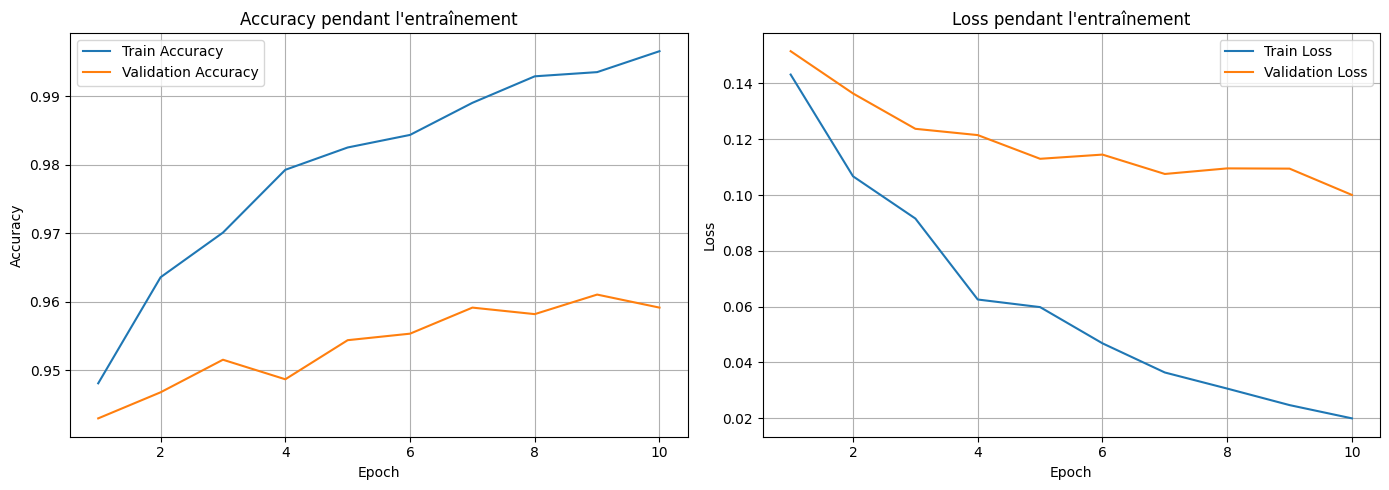

In [ ]:
# Visualiser les courbes d'apprentissage

import matplotlib.pyplot as plt

acc = history_finetuning.history["accuracy"]

val_acc = history_finetuning.history["val_accuracy"]

loss = history_finetuning.history["loss"]
val_loss = history_finetuning.history["val_loss"]

epochs_range = range(1, len(acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, acc, label="Train Accuracy")
axes[0].plot(epochs_range, val_acc, label="Validation Accuracy")
axes[0].set_title("Accuracy pendant l'entraînement")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_range, loss, label="Train Loss")
axes[1].plot(epochs_range, val_loss, label="Validation Loss")
axes[1].set_title("Loss pendant l'entraînement")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


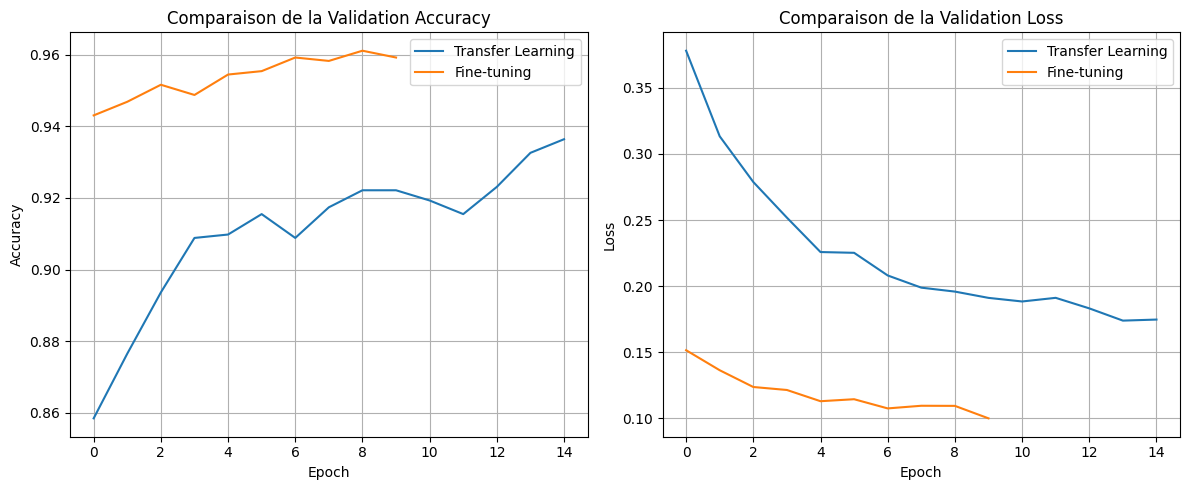

In [ ]:
# Comparer les courbes des deux phases
plt.figure(figsize=(12, 5))

# Comparaison de la validation accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["val_accuracy"], label="Transfer Learning")
plt.plot(
    history_finetuning.history["val_accuracy"],
    label="Fine-tuning"
)
plt.title("Comparaison de la Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Comparaison de la validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history["val_loss"], label="Transfer Learning")
plt.plot(
    history_finetuning.history["val_loss"],
    label="Fine-tuning"
)
plt.title("Comparaison de la Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()